В цьому ноутбуці відбуваєтся тестування рандомних активів на рандомному проміжку часу. Метою є візуальна перевірка коректність роботи бектест алгоритму

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import random

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
sequence_length = 365 * 5

In [5]:
token_num = 10

random_token = random.sample(df_stocks.columns.tolist(), token_num)
random_token

['XMR', 'ADA', 'XLM', 'SOL', 'BTC', 'DOGE', 'ETH', 'LINK', 'XRP', 'DOT']

In [6]:
# strategy={"extra_buy_amount": 500}
strategy={}

05:06:23 - cmdstanpy - INFO - Chain [1] start processing
05:06:23 - cmdstanpy - INFO - Chain [1] done processing


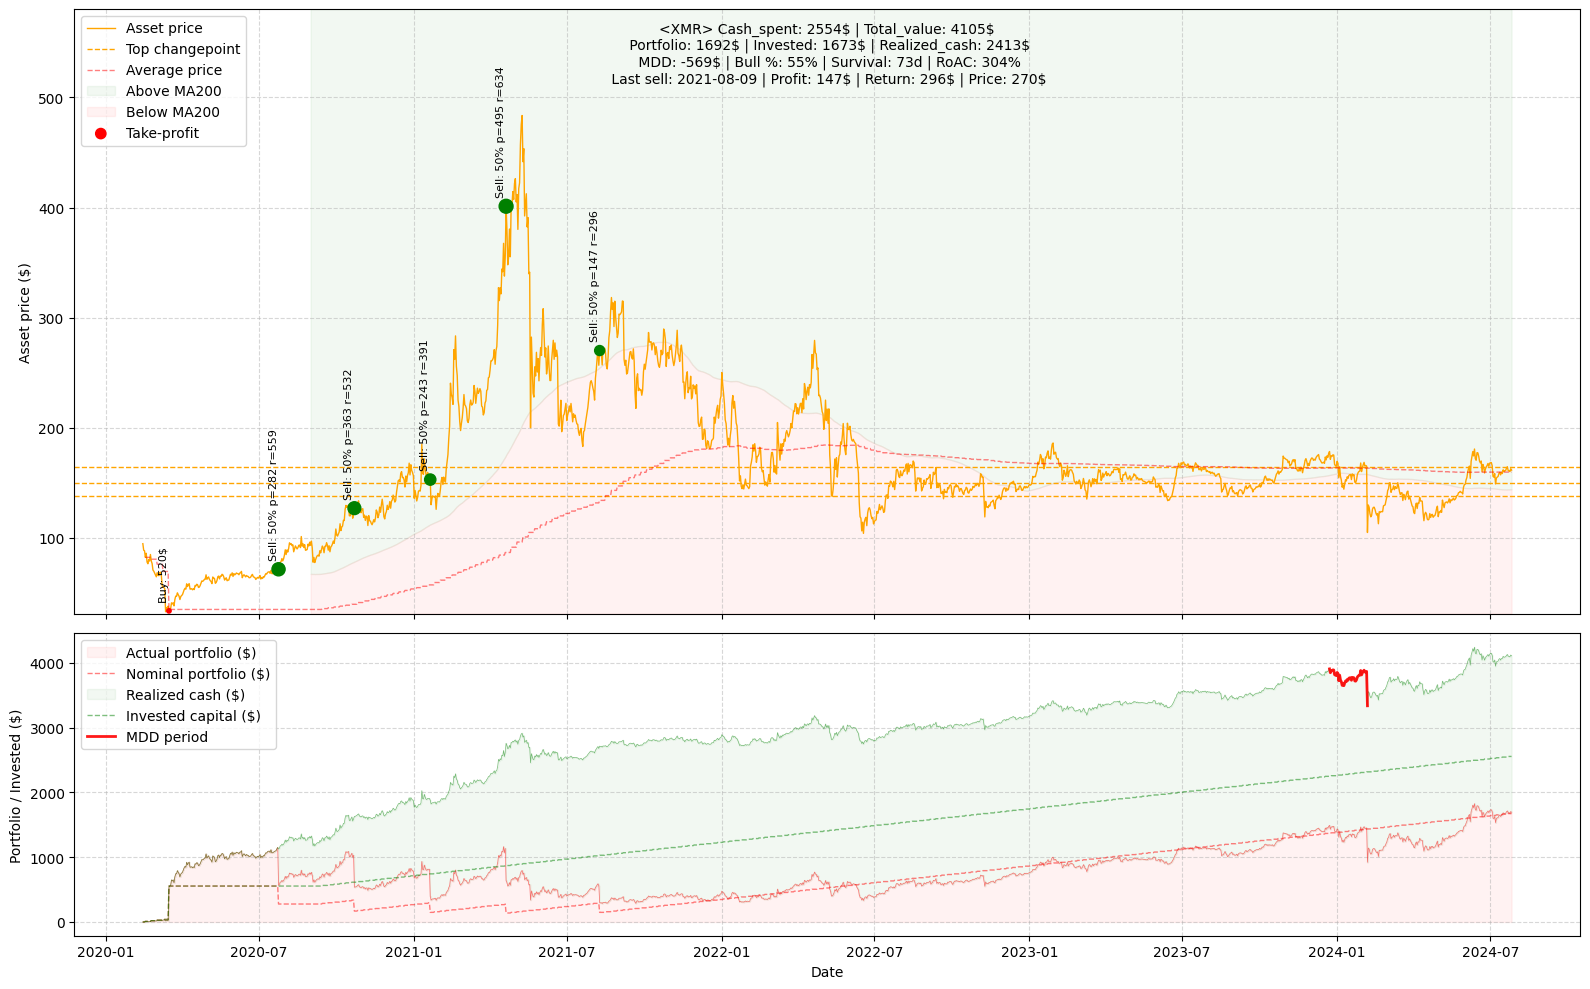

05:06:24 - cmdstanpy - INFO - Chain [1] start processing
05:06:24 - cmdstanpy - INFO - Chain [1] done processing


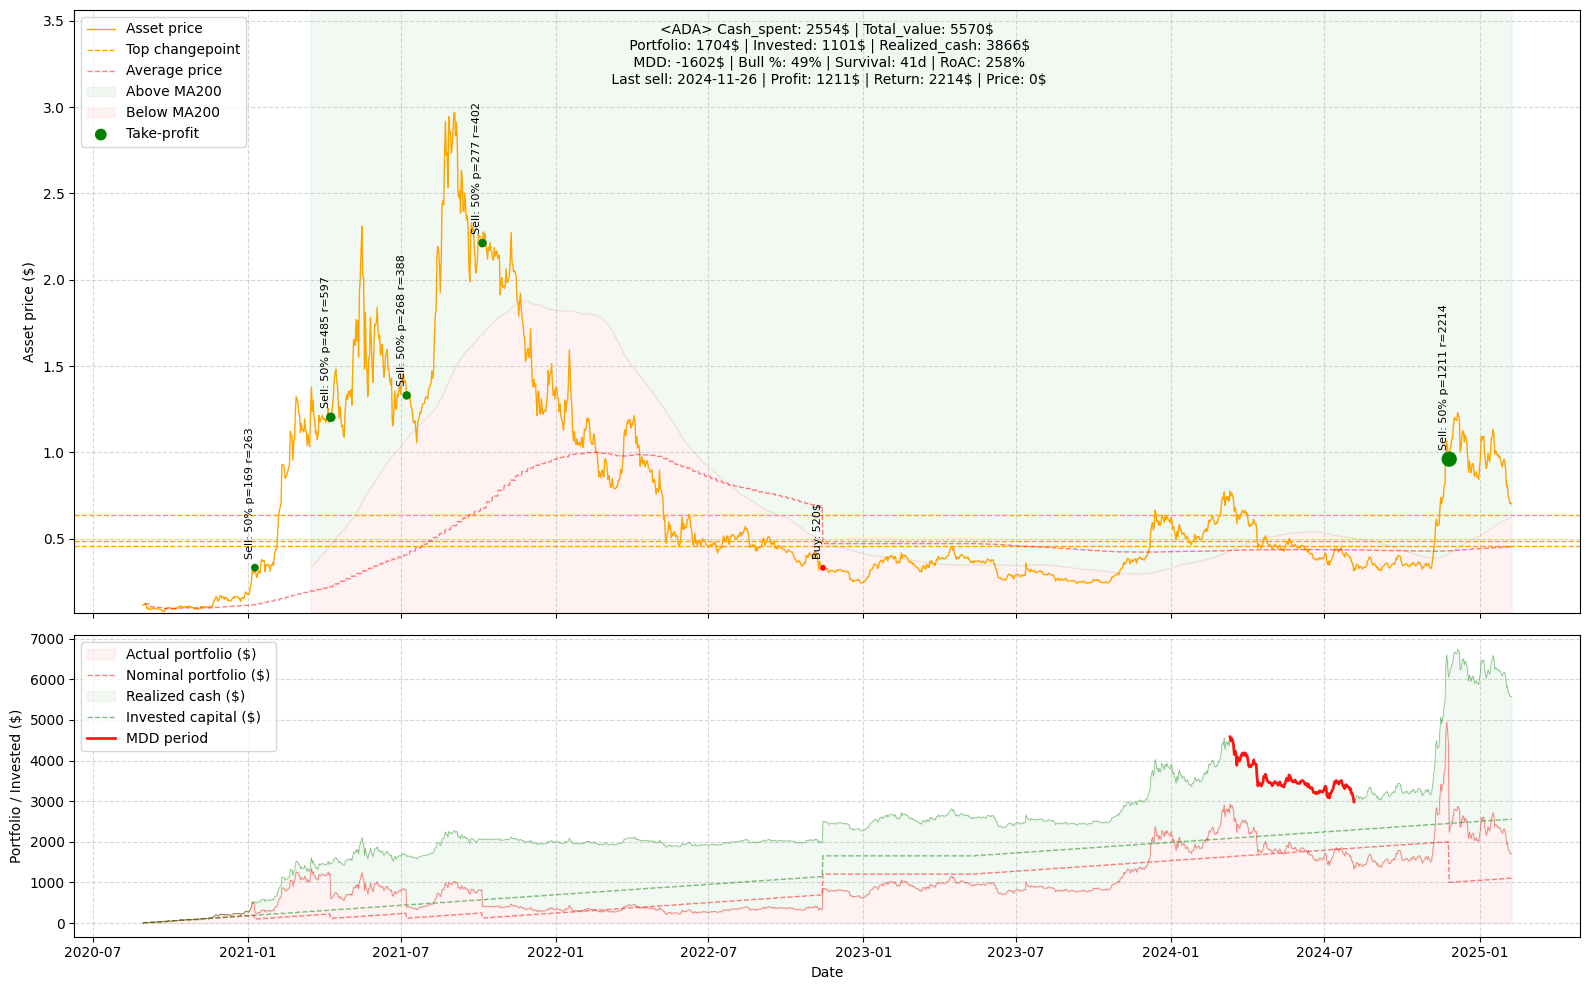

05:06:24 - cmdstanpy - INFO - Chain [1] start processing
05:06:24 - cmdstanpy - INFO - Chain [1] done processing


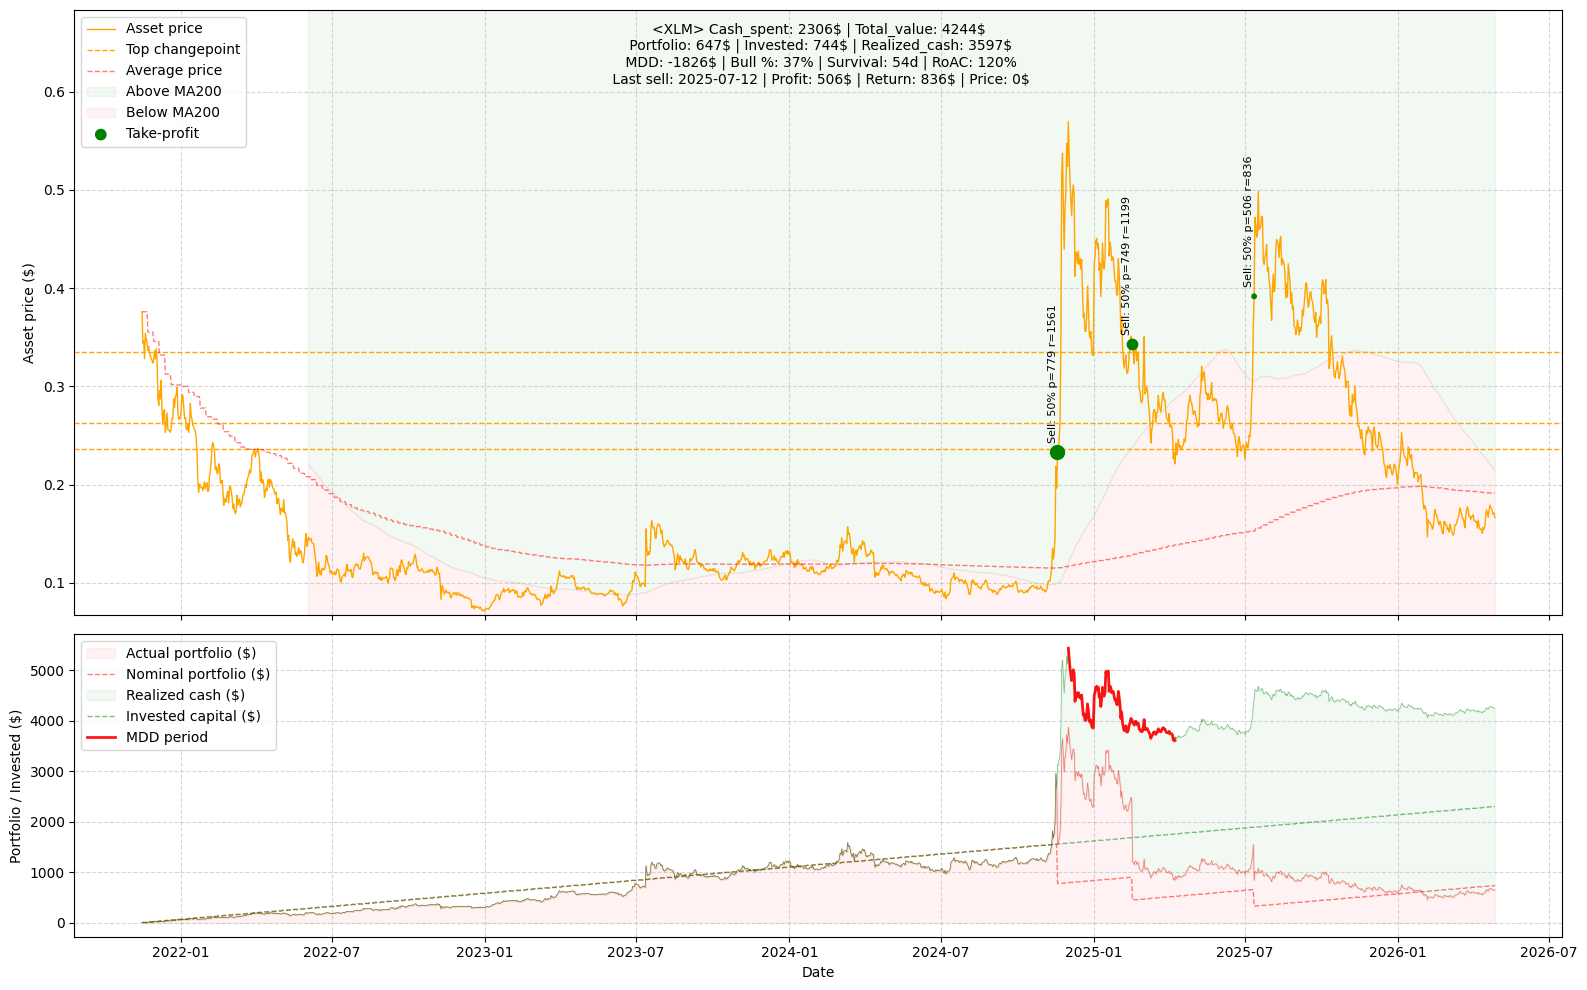

05:06:25 - cmdstanpy - INFO - Chain [1] start processing
05:06:25 - cmdstanpy - INFO - Chain [1] done processing


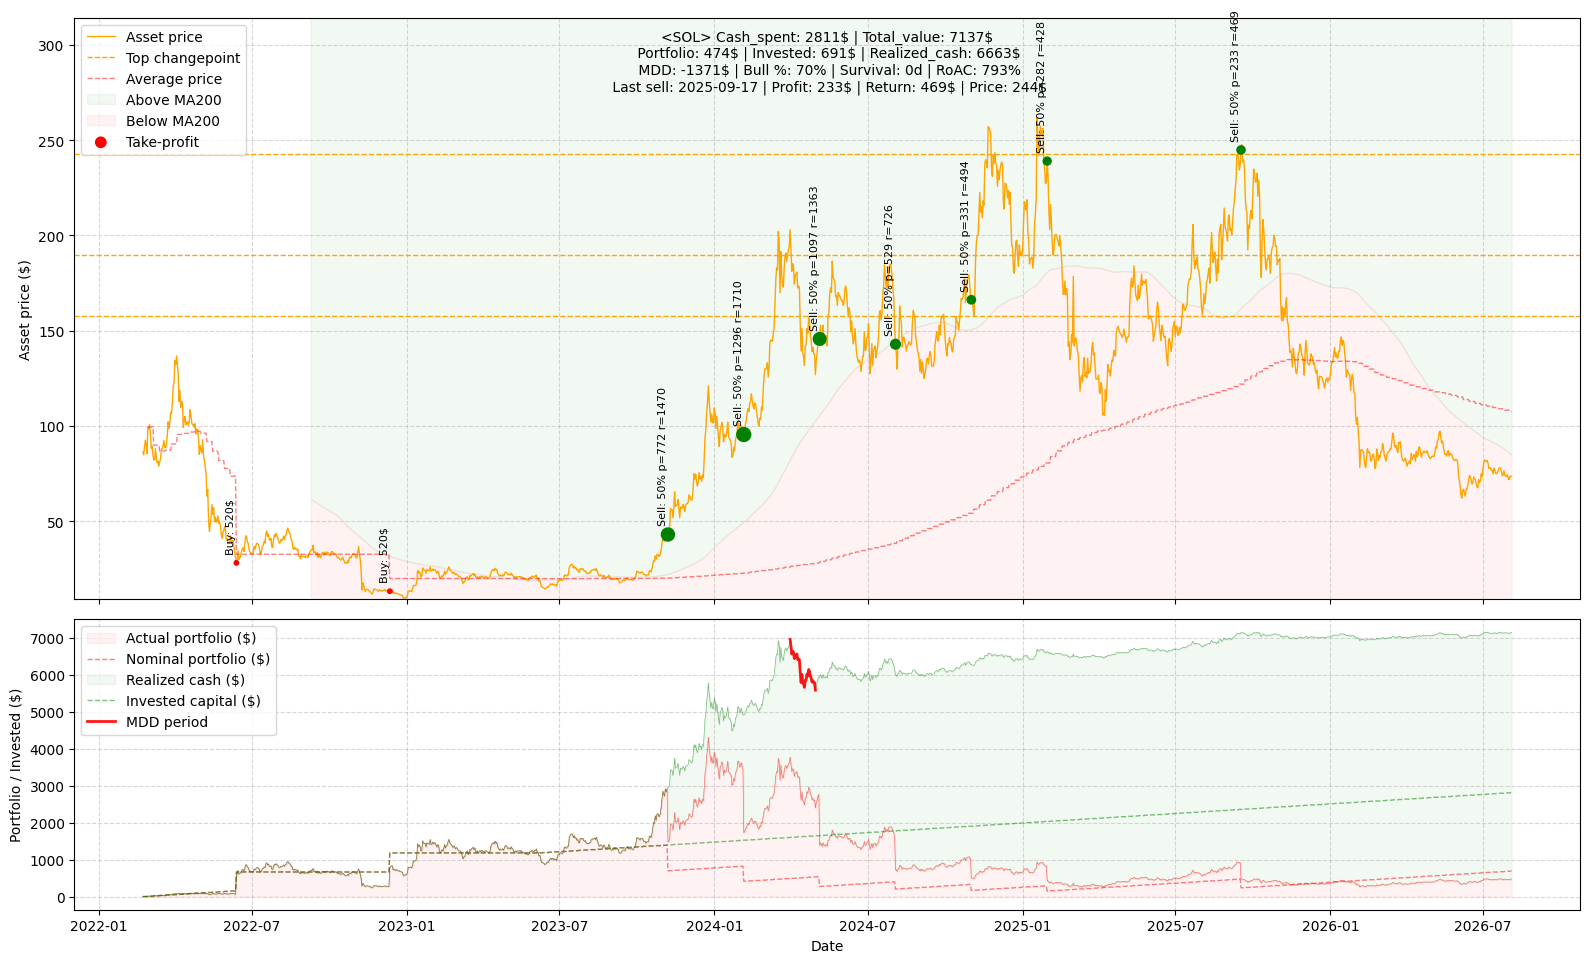

05:06:25 - cmdstanpy - INFO - Chain [1] start processing
05:06:25 - cmdstanpy - INFO - Chain [1] done processing


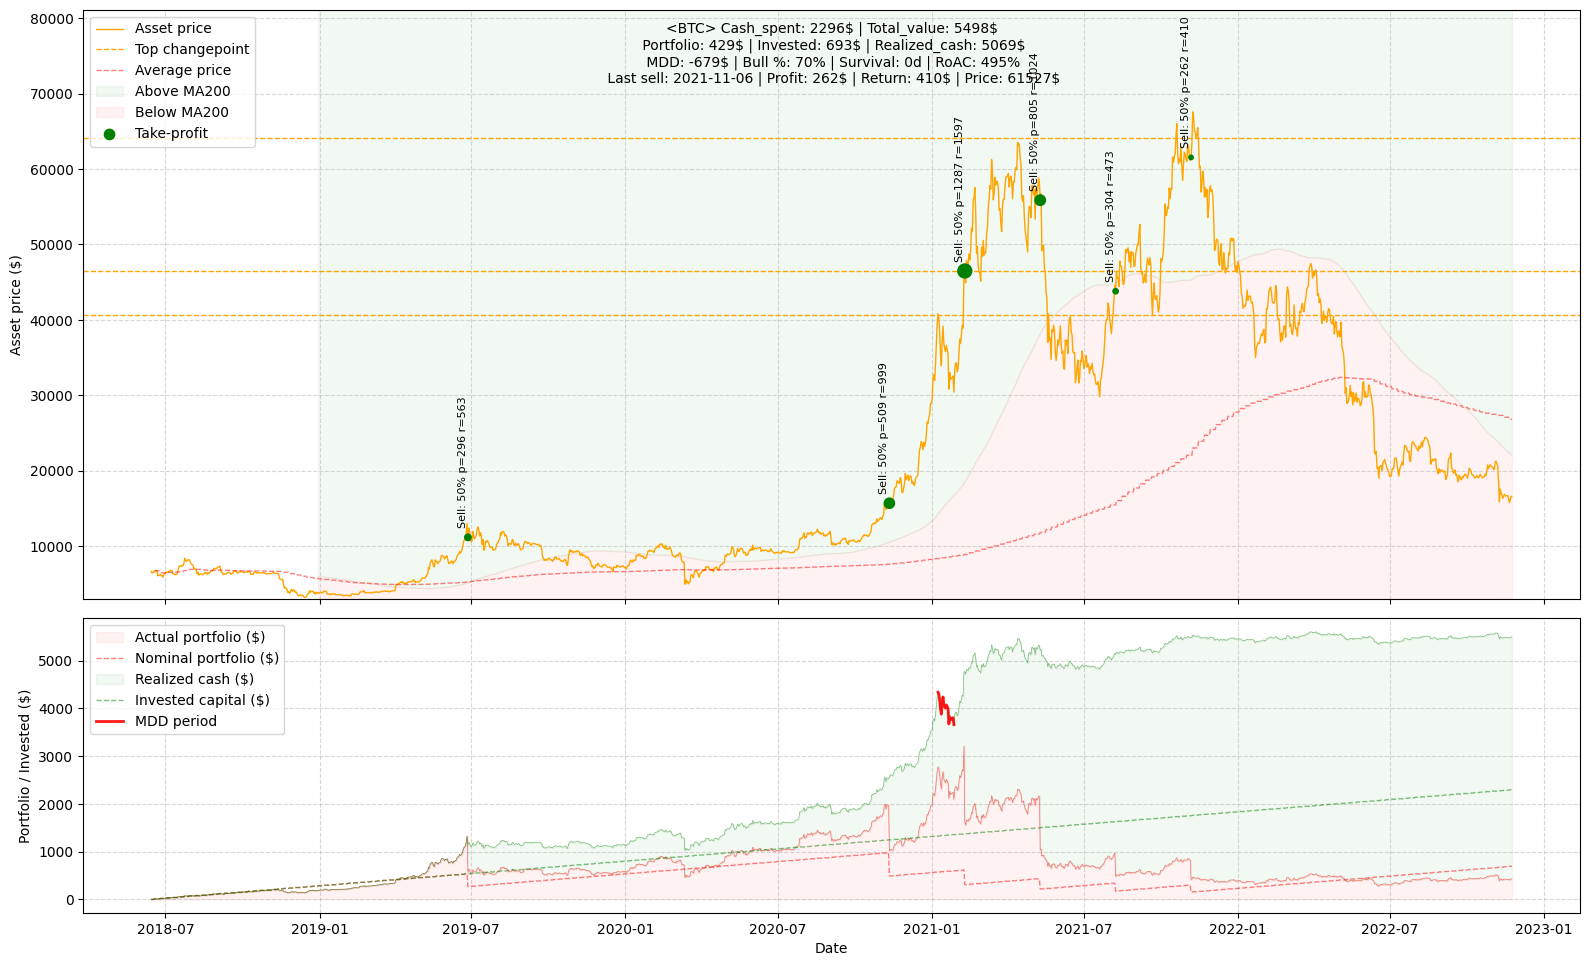

05:06:26 - cmdstanpy - INFO - Chain [1] start processing
05:06:26 - cmdstanpy - INFO - Chain [1] done processing


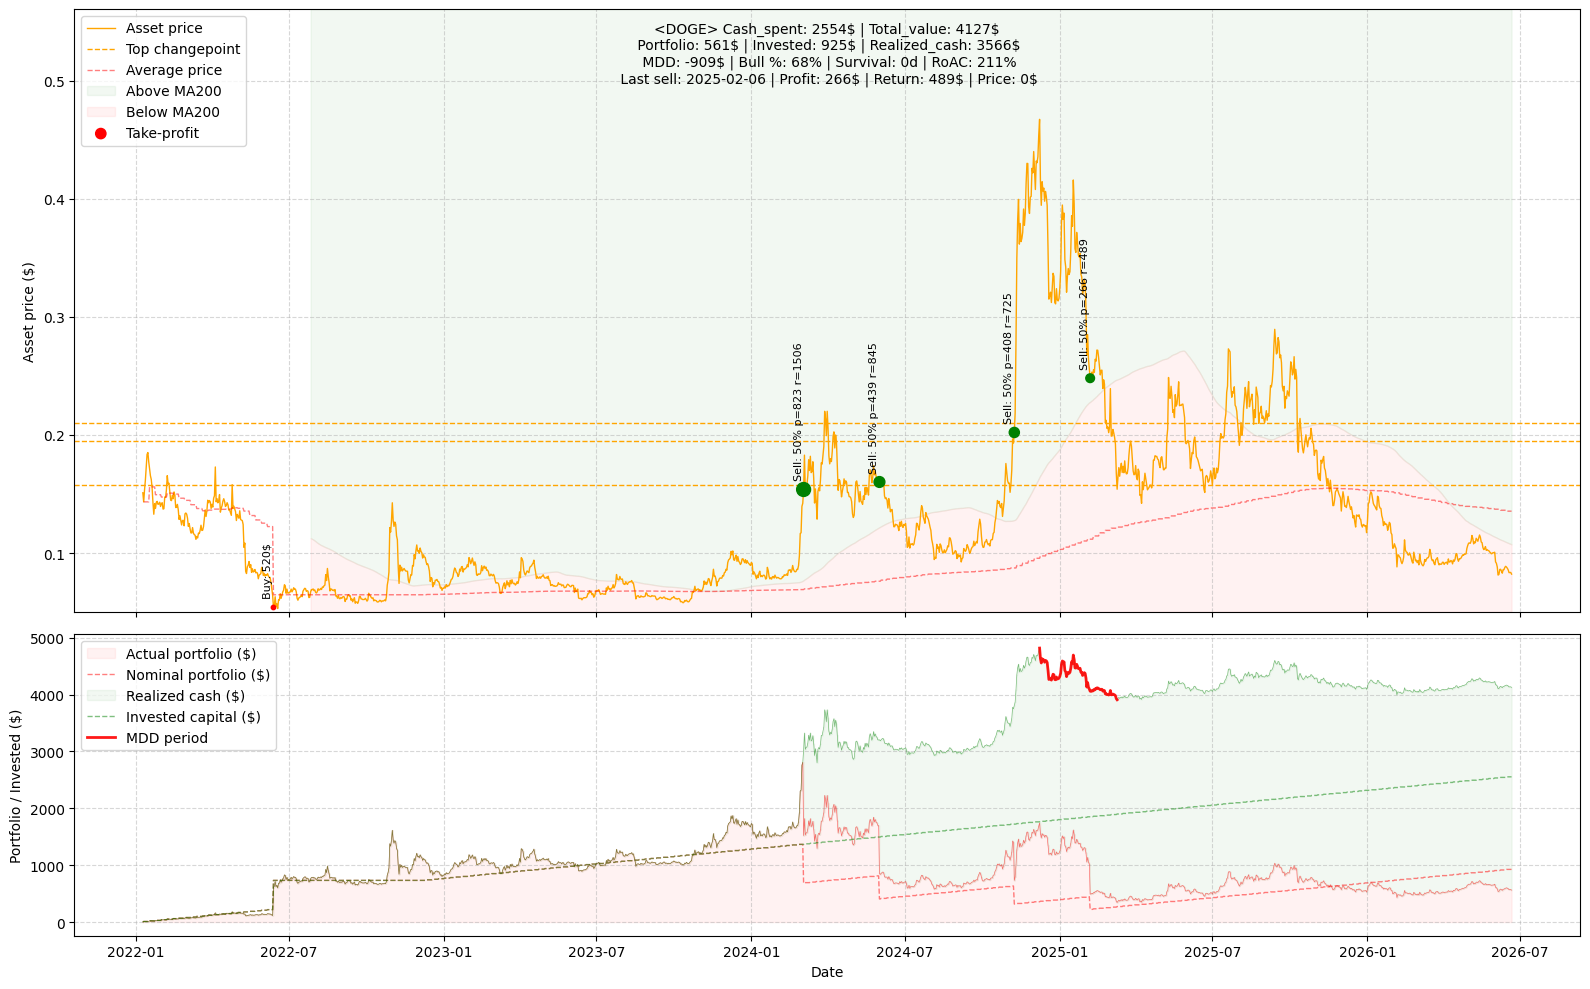

05:06:26 - cmdstanpy - INFO - Chain [1] start processing
05:06:27 - cmdstanpy - INFO - Chain [1] done processing


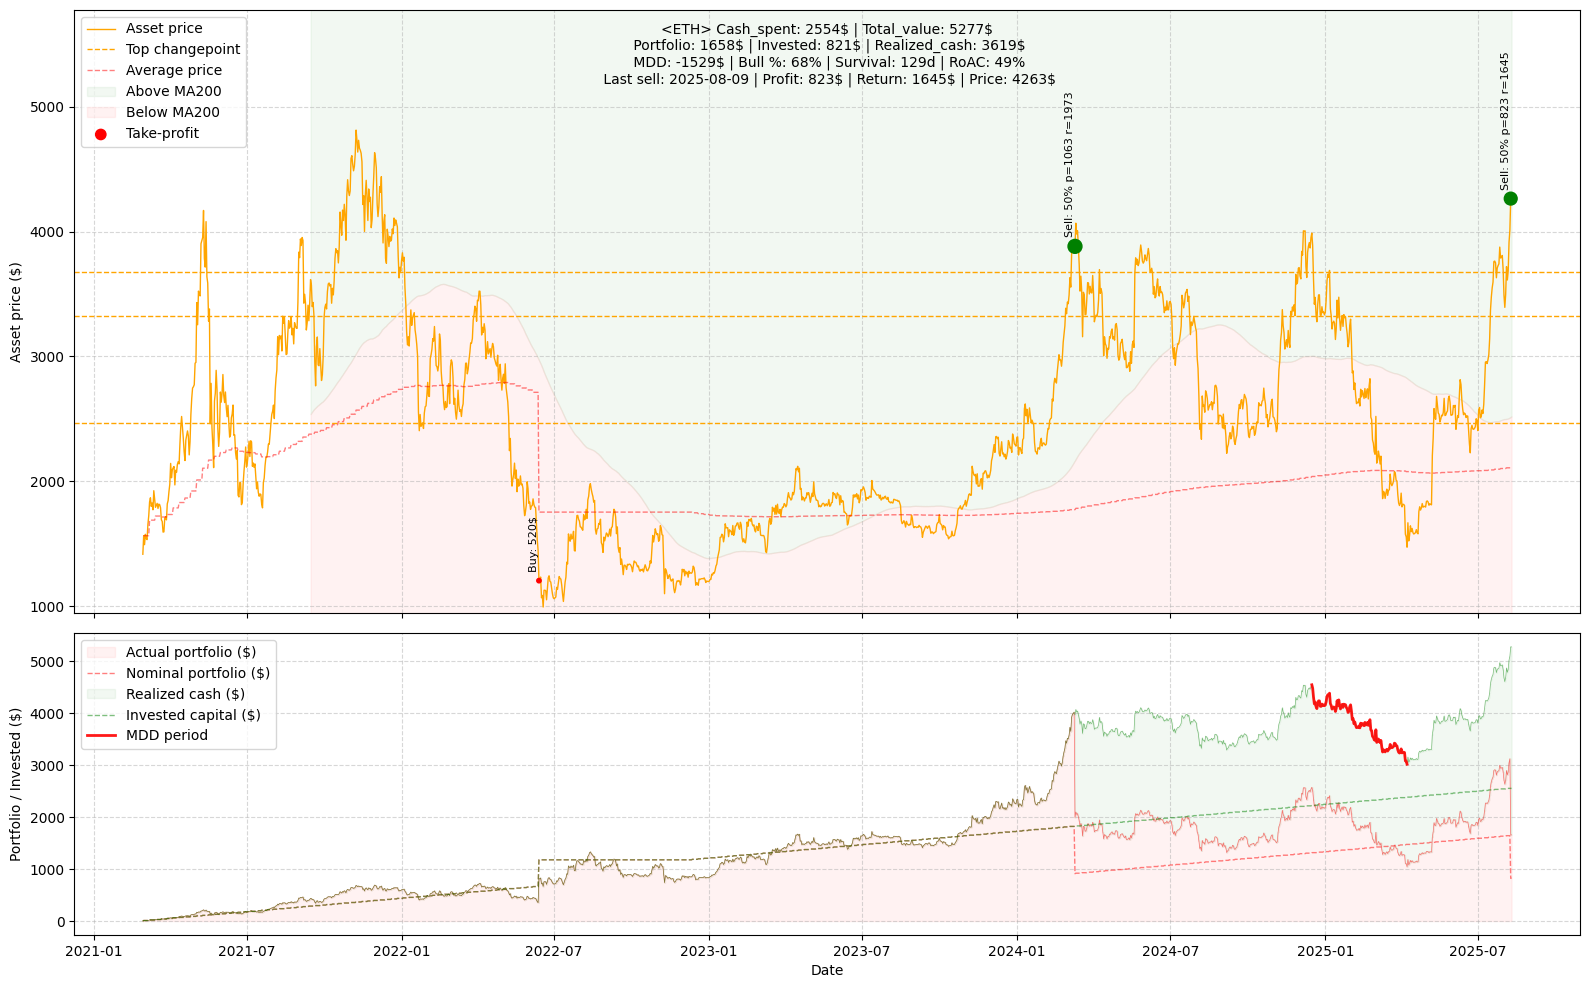

05:06:27 - cmdstanpy - INFO - Chain [1] start processing
05:06:27 - cmdstanpy - INFO - Chain [1] done processing


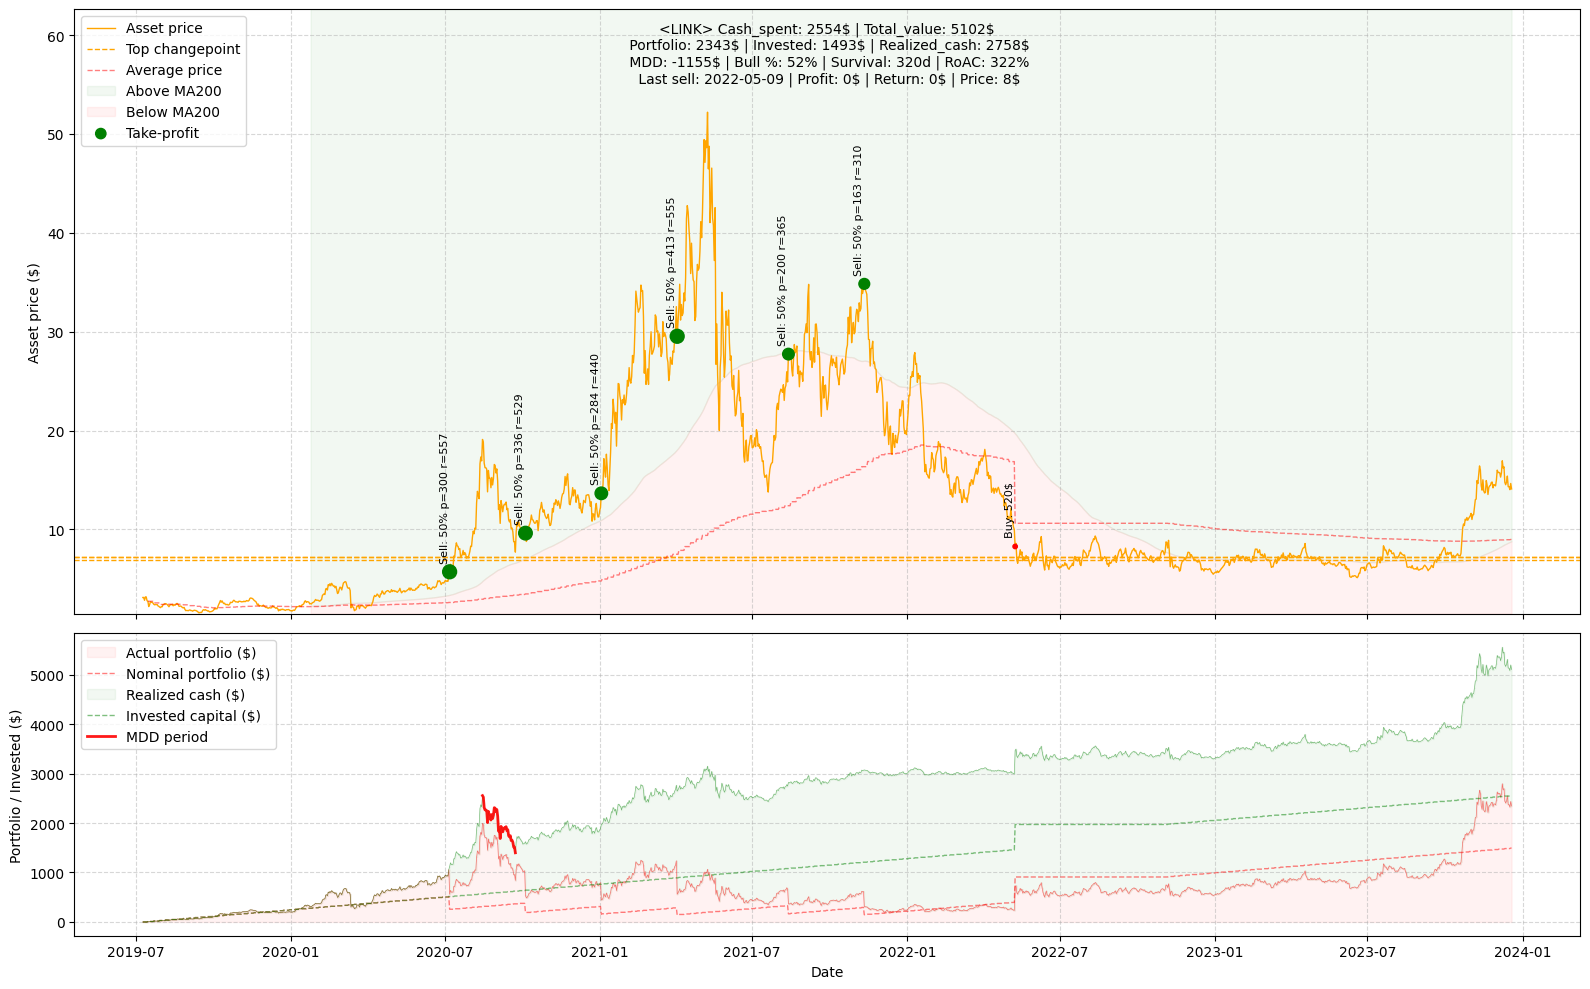

05:06:28 - cmdstanpy - INFO - Chain [1] start processing
05:06:28 - cmdstanpy - INFO - Chain [1] done processing


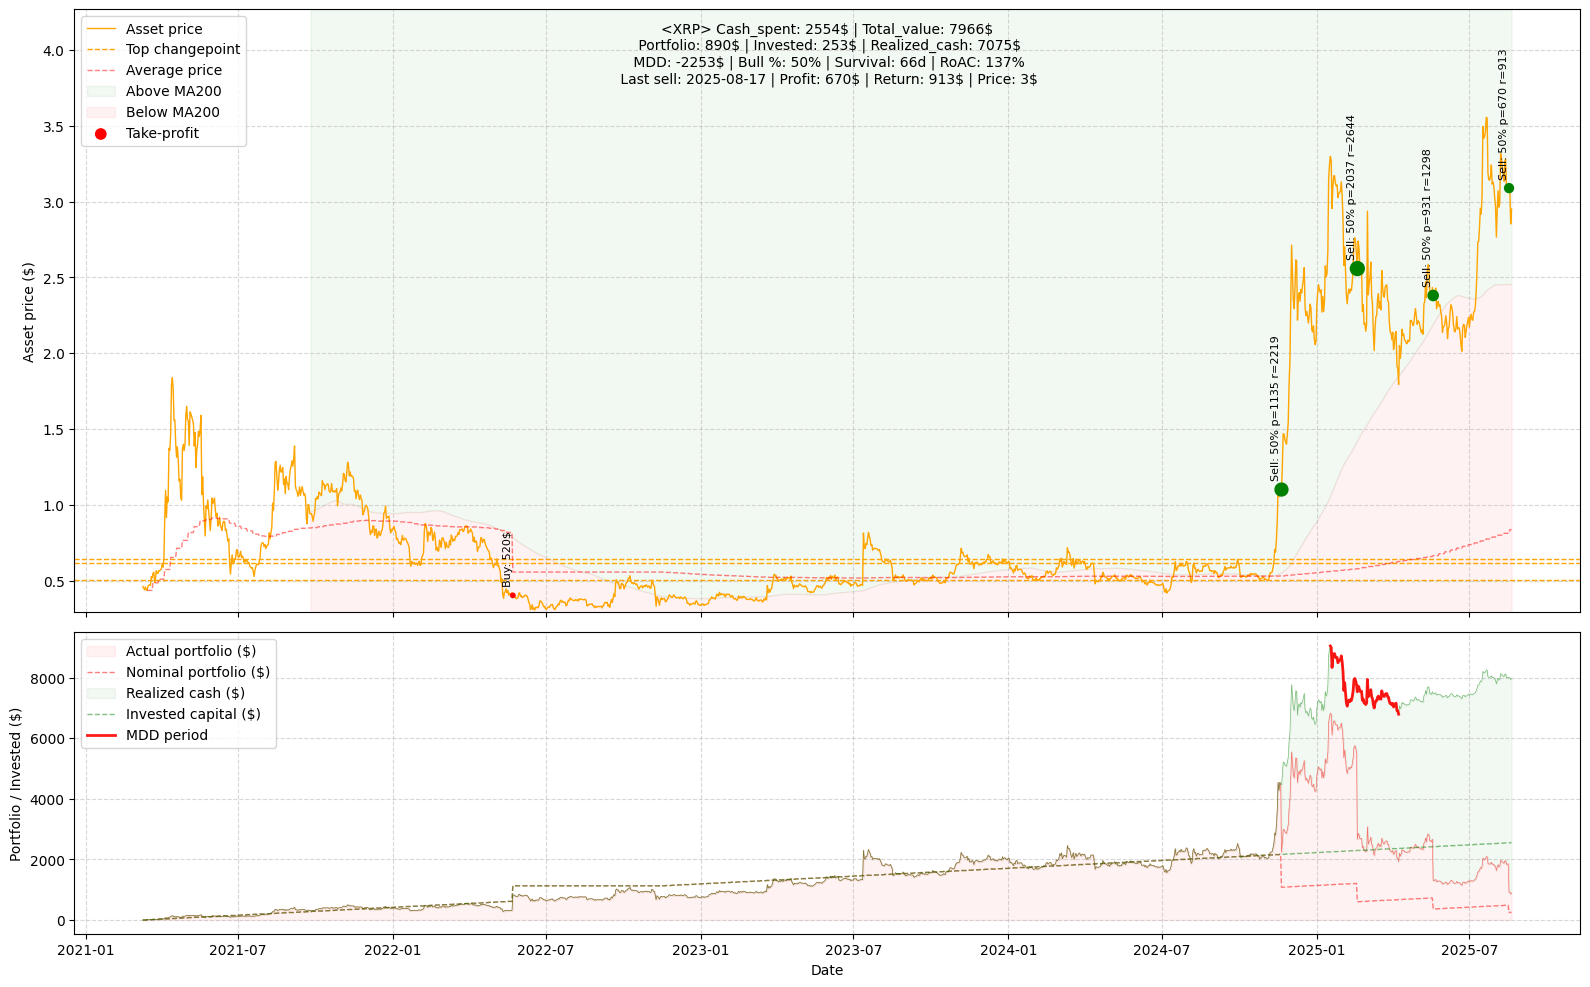

05:06:28 - cmdstanpy - INFO - Chain [1] start processing
05:06:29 - cmdstanpy - INFO - Chain [1] done processing


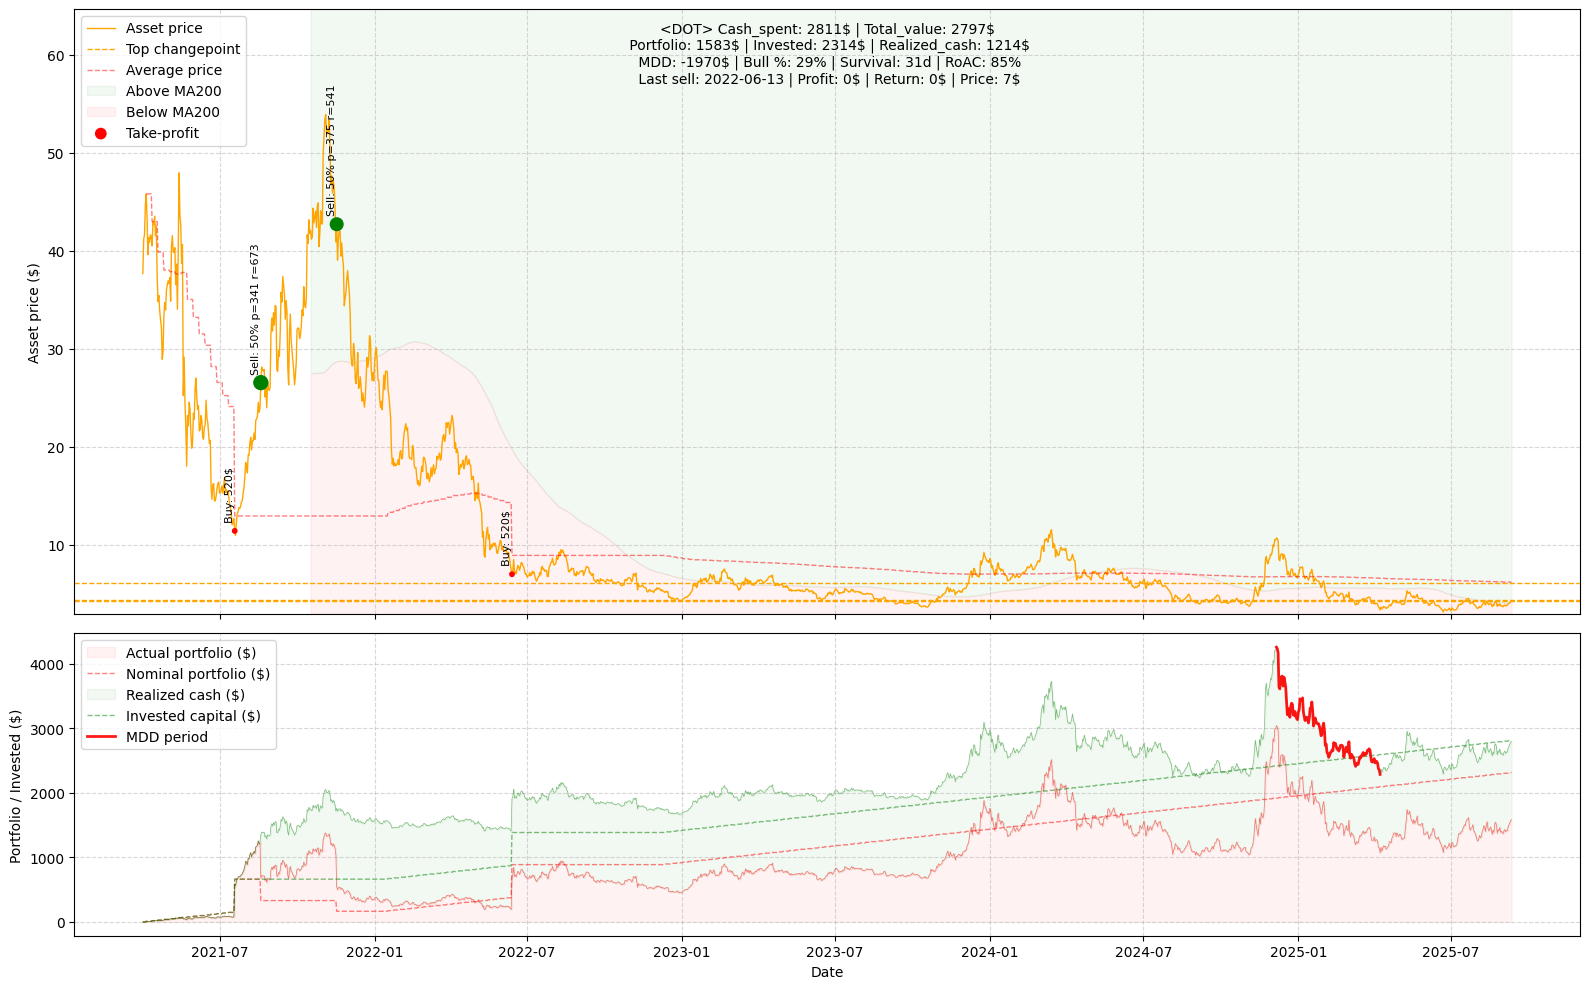

Total invested: $25548.00
Total return: $39840.00
Total value: $51823.00


In [7]:
total_invested = 0
total_profit = 0
total_return = 0
total_value = 0

for stock in random_token:

    prices = df_stocks[stock]
    prices = prices.dropna()
    start = random.randint(0, len(prices) - sequence_length)
    prices = prices.iloc[start:start + sequence_length]
    prices = prices.iloc[200:]

    try:
        bt = BacktestDCA(
        target=stock,
        prices=prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {stock}: {e}")
        continue

    total_invested += metrics['Cash_spent']
    total_return += metrics['Realized_cash']
    total_value += metrics['Total_value']

print(f"Total invested: ${total_invested:.2f}")
print(f"Total return: ${total_return:.2f}")
print(f"Total value: ${total_value:.2f}")

In [8]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2021-04-01,37.672878,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-04-02,41.164284,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-04-03,41.646030,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-04-04,44.652210,0.000000,0.000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2021-04-05,45.797230,0.216170,9.900,9.9,0.0,0.0,0.000000,,9.900000,45.797230,9.900000
...,...,...,...,...,...,...,...,...,...,...,...
2025-09-07,3.994867,370.854104,2304.225,2801.7,0.0,0.0,1214.447186,,1481.512855,6.213292,2695.960041
2025-09-08,4.045087,373.301518,2314.125,2811.6,0.0,0.0,1214.447186,,1510.037064,6.199077,2724.484250
2025-09-09,4.139012,373.301518,2314.125,2811.6,0.0,0.0,1214.447186,,1545.099409,6.199077,2759.546595


In [9]:
(result['Portfolio'] > 0).sum()

np.int64(1621)

In [10]:
metrics

{'Target': 'DOT',
 'Cash_spent': 2811,
 'Realized_cash': 1214,
 'Portfolio': 1583,
 'Invested': 2314,
 'Total_value': 2797,
 'Bull_history': 29,
 'Avg_price': np.float64(6.199077396119295),
 'Num_take_profits': 4,
 'MDD': -1970,
 'MA200_survival_days': 31.09999999999999,
 'RoAC': 85}